# Práctica 3 · Predicción de la deserción estudiantil

**Materia:** Introducción a la Ciencia de Datos 2026

**Objetivo:** construir un clasificador que, al cierre del primer semestre, prediga la situación de cada estudiante al final de la duración normal de su carrera (*graduado*, *desertor* o *todavía inscrito*), y comparar cinco clasificadores llevados a su mejor versión: árbol de decisión, Naive Bayes, kNN, SVM y regresión logística.

> Se utilizó el asistente de inteligencia artificial Claude (Anthropic) en la elaboración de este notebook. La autora revisó el contenido y es responsable de su exactitud.

### Contenido
1. Configuración y versiones
2. El problema y los datos
3. Información disponible al momento de decidir
4. Protocolo de evaluación común
5. Preprocesamiento y búsqueda de hiperparámetros (herramientas comunes)
6. Los cinco clasificadores: árbol de decisión, Naive Bayes, kNN, SVM y regresión logística
7. Comparación de los clasificadores optimizados
8. Matriz de confusión del mejor clasificador y análisis de la clase desertor
9. ¿Conviene esperar al cierre del segundo semestre?
10. Clasificador final y predicciones de prueba
11. Discusión y conclusiones

## 1. Configuración y versiones

Todas las fuentes de aleatoriedad (pliegues, búsquedas aleatorias, modelos con componente aleatoria) usan la misma semilla `SEMILLA`. Las rutas son relativas a la raíz del repositorio.

In [1]:
import sys, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, recall_score, confusion_matrix
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, KBinsDiscretizer
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
import scipy
from scipy.stats import loguniform, randint, uniform

SEMILLA = 42
np.random.seed(SEMILLA)

DIR_DATOS = Path("datos")
RUTA_ENTRENAMIENTO = DIR_DATOS / "desercion-entrenamiento.csv"
RUTA_PRUEBA = DIR_DATOS / "desercion-prueba.csv"
RUTA_PREDICCIONES = Path("predicciones.csv")

# KBinsDiscretizer avisa cuando un atributo de conteo tiene cuantiles repetidos y fusiona esos
# intervalos; es el comportamiento deseado, así que se silencia solo ese aviso.
warnings.filterwarnings("ignore", message="Bins whose width are too small")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

versiones = {
    "Python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
}
pd.Series(versiones, name="versión").to_frame()

,versión
Python,3.13.18
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2


Colores fijos por clase, usados en todas las gráficas del notebook (paleta categórica validada para daltonismo):

In [2]:
CLASES = ["dropout", "enrolled", "graduate"]          # orden fijo en todo el notebook
NOMBRES_CLASE = {"dropout": "Desertor", "enrolled": "Inscrito", "graduate": "Graduado"}
COLOR_CLASE = {"dropout": "#2a78d6", "enrolled": "#eb6834", "graduate": "#1baf7a"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3dd",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

## 2. El problema y los datos

Los datos son 4424 estudiantes de licenciatura del Instituto Politécnico de Portalegre (Portugal) que ingresaron entre los ciclos 2008/09 y 2018/19 (Realinho *et al.*, 2022; [UCI 697](https://archive.ics.uci.edu/dataset/697)). Cada estudiante se describe con lo que se sabía al inscribirse (datos demográficos, socioeconómicos y académicos previos), con su desempeño en el primer y el segundo semestres y con tres indicadores macroeconómicos.

La variable objetivo `Target` es la situación al final de la duración normal de la carrera (tres años; cuatro en Enfermería):

- **Dropout** (desertor): abandonó; incluye cambios de carrera o de institución, sin importar cuándo ocurrieron.
- **Enrolled** (inscrito): sigue inscrito, pero no terminó en el tiempo normal.
- **Graduate** (graduado): terminó en el tiempo normal.

El curso repartió los estudiantes en dos archivos con una partición estratificada por `Target`: 3539 para entrenamiento (con `Target`) y 885 para prueba (sin `Target` ni atributos del segundo semestre).

In [3]:
entrenamiento = pd.read_csv(RUTA_ENTRENAMIENTO)
prueba = pd.read_csv(RUTA_PRUEBA)

# Etiquetas en minúsculas, como las pide el archivo de entrega
entrenamiento["Target"] = entrenamiento["Target"].str.lower()

print(f"Entrenamiento: {entrenamiento.shape[0]} filas × {entrenamiento.shape[1]} columnas")
print(f"Prueba:        {prueba.shape[0]} filas × {prueba.shape[1]} columnas")
print(f"Valores faltantes: entrenamiento {entrenamiento.isna().sum().sum()}, prueba {prueba.isna().sum().sum()}")
print(f"Filas duplicadas (sin id): {entrenamiento.drop(columns='id').duplicated().sum()}")
print(f"ids compartidos entre archivos: {len(set(entrenamiento['id']) & set(prueba['id']))}")
entrenamiento.head()

Entrenamiento: 3539 filas × 38 columnas
Prueba:        885 filas × 31 columnas
Valores faltantes: entrenamiento 0, prueba 0
Filas duplicadas (sin id): 0
ids compartidos entre archivos: 0


,id,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,1,1,2,9500,1,1,140.0,1,38,37,5,6,124.3,1,0,0,1,0,1,19,0,0,7,9,7,13.312500,0,0,8,8,8,15.637500,0,13.9,-0.3,0.79,graduate
1,2,1,17,1,8014,0,1,125.0,1,37,37,5,6,122.2,1,0,1,1,0,0,19,0,0,6,6,6,12.166667,0,0,6,7,6,11.666667,0,10.8,1.4,1.74,graduate
2,3,1,39,1,9991,0,1,130.0,1,1,1,9,7,152.1,0,0,0,1,1,0,28,0,0,5,13,2,11.000000,0,0,5,12,1,12.000000,0,11.1,0.6,2.02,dropout
3,4,1,42,1,8014,0,1,150.0,1,19,2,4,6,148.0,0,0,0,1,0,0,26,0,0,6,10,3,11.666667,0,0,6,8,5,12.000000,0,9.4,-0.8,-3.12,graduate
4,5,2,42,1,9254,1,1,136.0,1,2,2,134,112,130.0,1,0,0,1,1,0,22,0,2,6,13,4,11.500000,0,2,6,12,2,12.500000,0,7.6,2.6,0.32,dropout


### 2.1 Distribución de las clases

,clase,estudiantes,proporción
dropout,Desertor,1137,0.321
enrolled,Inscrito,635,0.179
graduate,Graduado,1767,0.499


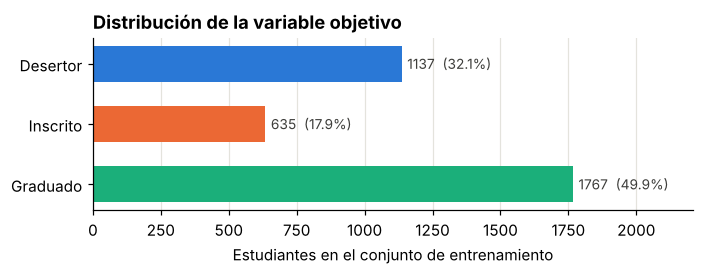

In [4]:
conteo = entrenamiento["Target"].value_counts().reindex(CLASES)
dist = pd.DataFrame({
    "clase": [NOMBRES_CLASE[c] for c in CLASES],
    "estudiantes": conteo.values,
    "proporción": (conteo / conteo.sum()).round(3).values,
}, index=CLASES)
display(dist)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
y = np.arange(len(CLASES))
ax.barh(y, conteo.values, color=[COLOR_CLASE[c] for c in CLASES], height=0.6)
for i, (n, p) in enumerate(zip(conteo.values, dist["proporción"])):
    ax.text(n + 20, i, f"{n}  ({p:.1%})", va="center", fontsize=9, color="#3d3d3a")
ax.set_yticks(y, [NOMBRES_CLASE[c] for c in CLASES])
ax.invert_yaxis()
ax.set_xlim(0, conteo.max() * 1.25)
ax.set_xlabel("Estudiantes en el conjunto de entrenamiento")
ax.grid(axis="y", visible=False)
ax.set_title("Distribución de la variable objetivo")
plt.tight_layout()
plt.show()

Las clases están desbalanceadas: la mitad de los estudiantes se gradúa, un tercio deserta y menos de uno de cada cinco sigue inscrito. Con esta distribución la exactitud premiaría a un modelo que ignora la clase *inscrito*; por eso la métrica principal es el **F1 macro**, que da el mismo peso a las tres clases, y por eso se ajustan los pesos por clase (`class_weight`) en los clasificadores que los admiten.

### 2.2 Tipo de cada atributo

La escala de medición de cada atributo se tomó de la descripción de los datos del curso (`datos/README.md`) y de la ficha de UCI. La escala decide el preprocesamiento: los atributos **nominales** vienen codificados como enteros, pero sus códigos no tienen orden ni distancia (el código 9991 de `Course` no es "mayor" que el 33), así que tratarlos como números sería un error para kNN, SVM y regresión logística.

In [5]:
NOMINALES = [            # nominales con más de dos niveles, codificados como enteros
    "Marital status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]
BINARIAS = [             # nominales con dos niveles, ya codificadas 0/1
    "Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "International",
]
ORDINALES = ["Application order"]   # 0 = primera opción ... 9
NUMERICAS_PREVIAS = [    # intervalo o razón, conocidas al inscribirse
    "Previous qualification (grade)", "Admission grade", "Age at enrollment",
]
SEM1 = [
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
]
SEM2 = [c.replace("1st sem", "2nd sem") for c in SEM1]
MACRO = ["Unemployment rate", "Inflation rate", "GDP"]

NUMERICAS = NUMERICAS_PREVIAS + SEM1 + MACRO

ESCALA = {
    **{c: "nominal" for c in NOMINALES}, **{c: "nominal binaria" for c in BINARIAS},
    **{c: "ordinal" for c in ORDINALES},
    "Previous qualification (grade)": "intervalo (0–200)", "Admission grade": "intervalo (0–200)",
    "Age at enrollment": "razón (años)",
    **{c: "razón (conteo)" for c in SEM1 + SEM2 if "grade" not in c},
    "Curricular units 1st sem (grade)": "intervalo (0–20)", "Curricular units 2nd sem (grade)": "intervalo (0–20)",
    "Unemployment rate": "razón (%)", "Inflation rate": "intervalo (%)", "GDP": "intervalo (%)",
}
ATRIBUTOS = [c for c in entrenamiento.columns if c not in ("id", "Target")]
assert set(ESCALA) == set(ATRIBUTOS), set(ATRIBUTOS) ^ set(ESCALA)

tipos = pd.DataFrame({
    "escala": [ESCALA[c] for c in ATRIBUTOS],
    "niveles distintos": [entrenamiento[c].nunique() for c in ATRIBUTOS],
    "mínimo": [entrenamiento[c].min() for c in ATRIBUTOS],
    "máximo": [entrenamiento[c].max() for c in ATRIBUTOS],
    "momento": ["2º semestre" if c in SEM2 else "1er semestre" if c in SEM1 else "inscripción" for c in ATRIBUTOS],
}, index=ATRIBUTOS)
tipos

,escala,niveles distintos,mínimo,máximo,momento
Marital status,nominal,6,1.00,6.000000,inscripción
Application mode,nominal,17,1.00,57.000000,inscripción
Application order,ordinal,8,0.00,9.000000,inscripción
Course,nominal,17,33.00,9991.000000,inscripción
Daytime/evening attendance,nominal binaria,2,0.00,1.000000,inscripción
Previous qualification,nominal,17,1.00,43.000000,inscripción
Previous qualification (grade),intervalo (0–200),100,95.00,190.000000,inscripción
Nacionality,nominal,18,1.00,109.000000,inscripción
Mother's qualification,nominal,26,1.00,44.000000,inscripción
Father's qualification,nominal,32,1.00,44.000000,inscripción


Varios atributos nominales tienen muchos niveles y la mayoría de esos niveles son raros. Además, el conjunto de prueba trae códigos que **no aparecen en el entrenamiento**; si el codificador no los contempla, el pipeline falla al predecir. Ambas cosas se resuelven en el preprocesamiento (agrupando los niveles poco frecuentes y tolerando los desconocidos).

In [6]:
resumen_nominales = pd.DataFrame({
    "niveles": [entrenamiento[c].nunique() for c in NOMINALES],
    "niveles con < 10 estudiantes": [(entrenamiento[c].value_counts() < 10).sum() for c in NOMINALES],
    "códigos de prueba no vistos": [sorted(set(prueba[c]) - set(entrenamiento[c])) for c in NOMINALES],
}, index=NOMINALES)
resumen_nominales

,niveles,niveles con < 10 estudiantes,códigos de prueba no vistos
Marital status,6,2,[]
Application mode,17,4,[26]
Course,17,0,[]
Previous qualification,17,8,[]
Nacionality,18,13,"[13, 14, 32]"
Mother's qualification,26,16,"[10, 18, 27]"
Father's qualification,32,21,"[13, 18]"
Mother's occupation,31,18,[171]
Father's occupation,45,31,[101]


## 3. Información disponible al momento de decidir

La predicción se hace **al cierre del primer semestre**. En ese momento se conocen los datos de inscripción, el desempeño del primer semestre y los indicadores macroeconómicos del año, pero no el desempeño del segundo semestre. Por eso los cinco clasificadores se entrenan y comparan **solo con los 30 atributos que también trae el conjunto de prueba**. Los seis atributos del segundo semestre se reservan para la sección en la que se estima cuánto se ganaría si se esperara un semestre más.

In [7]:
ATRIBUTOS_1ER = NOMINALES + BINARIAS + ORDINALES + NUMERICAS   # 30 atributos
ATRIBUTOS_2DO = ATRIBUTOS_1ER + SEM2                           # 36 atributos (solo para la sección 'esperar')

assert set(ATRIBUTOS_1ER) == set(prueba.columns) - {"id"}, "los atributos no coinciden con los de prueba"
assert len(ATRIBUTOS_1ER) == 30 and len(ATRIBUTOS_2DO) == 36

X = entrenamiento[ATRIBUTOS_1ER]
X_2do = entrenamiento[ATRIBUTOS_2DO]
y = entrenamiento["Target"]
X_prueba = prueba[ATRIBUTOS_1ER]

pd.DataFrame({
    "atributos": [len(NOMINALES), len(BINARIAS), len(ORDINALES), len(NUMERICAS), len(ATRIBUTOS_1ER)],
}, index=["nominales (>2 niveles)", "nominales binarios", "ordinales", "numéricos", "total al cierre del 1er semestre"])

,atributos
nominales (>2 niveles),9
nominales binarios,8
ordinales,1
numéricos,12
total al cierre del 1er semestre,30


Un vistazo a la señal disponible: el número de unidades aprobadas en el primer semestre separa bien a los graduados del resto, pero los inscritos quedan en medio, traslapados con los desertores y los graduados. Esto anticipa que *inscrito* será la clase más difícil.

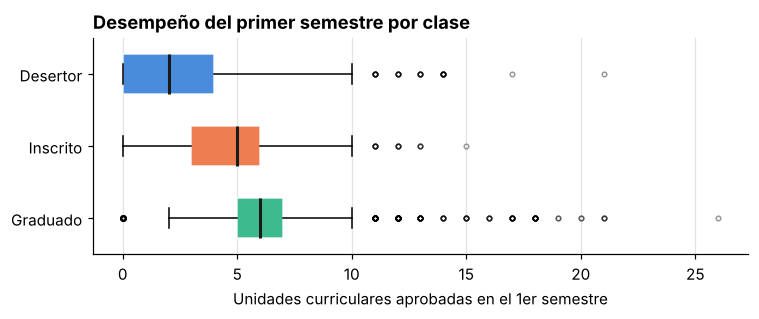

Target,dropout,enrolled,graduate
Curricular units 1st sem (approved),,,
aprobó ≥ 1 unidad,0.232,0.195,0.573
aprobó 0 unidades,0.786,0.100,0.114


In [8]:
col = "Curricular units 1st sem (approved)"
fig, ax = plt.subplots(figsize=(7, 3))
datos_box = [entrenamiento.loc[y == c, col] for c in CLASES]
horizontal = {"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10) else {"vert": False}
bp = ax.boxplot(datos_box, **horizontal, widths=0.55, patch_artist=True,
                medianprops=dict(color="#1a1a19", linewidth=2), flierprops=dict(markersize=3, alpha=0.4))
for caja, c in zip(bp["boxes"], CLASES):
    caja.set_facecolor(COLOR_CLASE[c]); caja.set_alpha(0.85); caja.set_edgecolor("white")
ax.set_yticks(range(1, 4), [NOMBRES_CLASE[c] for c in CLASES])
ax.invert_yaxis()
ax.set_xlabel("Unidades curriculares aprobadas en el 1er semestre")
ax.grid(axis="y", visible=False)
ax.set_title("Desempeño del primer semestre por clase")
plt.tight_layout()
plt.show()

pd.crosstab(entrenamiento[col] == 0, y, normalize="index").reindex(columns=CLASES).rename(
    index={True: "aprobó 0 unidades", False: "aprobó ≥ 1 unidad"}).round(3)

## 4. Protocolo de evaluación común

Para que la comparación sea justa, los cinco clasificadores comparten exactamente lo mismo:

- **Los mismos pliegues:** validación cruzada estratificada de 5 pliegues con barajado y semilla fija (`CV`). Se usa el mismo objeto en todas las búsquedas y evaluaciones, así que cada configuración de cada clasificador se evalúa sobre las mismas particiones.
- **La misma métrica de búsqueda:** F1 macro (`"f1_macro"`).
- **La misma función de evaluación** (`evaluar_cv`): reentrena el pipeline en cada pliegue y reporta el F1 macro por pliegue, la sensibilidad y la especificidad de cada clase y las predicciones fuera de pliegue (para la matriz de confusión).

Todo el preprocesamiento va dentro de un `Pipeline`, de modo que en cada pliegue el codificador y el escalador se ajustan solo con los datos de entrenamiento de ese pliegue.

In [9]:
N_PLIEGUES = 5
CV = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=SEMILLA)
PLIEGUES = list(CV.split(X, y))          # se materializan una vez para reutilizarlos tal cual
METRICA = "f1_macro"

# Comprobación: cada pliegue conserva la proporción de clases
pd.DataFrame(
    [y.iloc[val].value_counts(normalize=True).reindex(CLASES) for _, val in PLIEGUES],
    index=[f"pliegue {i+1}" for i in range(N_PLIEGUES)],
).round(3)

Target,dropout,enrolled,graduate
pliegue 1,0.321,0.179,0.500
pliegue 2,0.321,0.179,0.500
pliegue 3,0.322,0.179,0.499
pliegue 4,0.322,0.179,0.499
pliegue 5,0.321,0.180,0.499


In [10]:
def especificidad_por_clase(y_true, y_pred, clases=CLASES):
    # Especificidad uno-contra-resto: TN / (TN + FP) para cada clase.
    cm = confusion_matrix(y_true, y_pred, labels=clases)
    total = cm.sum()
    esp = []
    for k in range(len(clases)):
        tp = cm[k, k]
        fp = cm[:, k].sum() - tp
        fn = cm[k, :].sum() - tp
        tn = total - tp - fp - fn
        esp.append(tn / (tn + fp))
    return np.array(esp)


def evaluar_cv(modelo, X, y, pliegues=PLIEGUES):
    # Reentrena `modelo` en cada pliegue y devuelve métricas por pliegue y predicciones fuera de pliegue.
    filas = []
    pred_oof = pd.Series(index=y.index, dtype=object)
    for i, (ent, val) in enumerate(pliegues):
        m = clone(modelo).fit(X.iloc[ent], y.iloc[ent])
        p = m.predict(X.iloc[val])
        pred_oof.iloc[val] = p
        sens = recall_score(y.iloc[val], p, labels=CLASES, average=None)
        esp = especificidad_por_clase(y.iloc[val], p)
        fila = {"pliegue": i + 1, "f1_macro": f1_score(y.iloc[val], p, average="macro")}
        fila.update({f"sens_{c}": s for c, s in zip(CLASES, sens)})
        fila.update({f"esp_{c}": e for c, e in zip(CLASES, esp)})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("pliegue"), pred_oof


# Aquí se irán guardando los resultados de cada clasificador optimizado
RESULTADOS = {}   # nombre -> {"modelo", "busqueda", "por_pliegue", "pred_oof", "tiempo_busqueda_s", "n_config"}

Como referencia mínima, un clasificador que siempre predice la clase mayoritaria (*graduado*). Cualquier modelo útil debe superarlo con holgura.

In [11]:
from sklearn.dummy import DummyClassifier

ref_por_pliegue, _ = evaluar_cv(DummyClassifier(strategy="most_frequent"), X, y)
print(f"F1 macro de referencia (clase mayoritaria): "
      f"{ref_por_pliegue['f1_macro'].mean():.3f} ± {ref_por_pliegue['f1_macro'].std():.3f}")

F1 macro de referencia (clase mayoritaria): 0.222 ± 0.000


## 5. Preprocesamiento y búsqueda de hiperparámetros: herramientas comunes

### 5.1 Codificación de los atributos nominales

Los nueve atributos nominales con más de dos niveles se codifican con *one-hot* en todos los clasificadores, salvo en la variante categórica de Naive Bayes, que los usa directamente como categorías. Dos detalles de los datos, vistos en la sección 2.2, deciden cómo se configura el codificador:

- **Niveles raros.** Los niveles con menos de `MIN_FREC = 10` estudiantes en el pliegue de entrenamiento se agrupan en una sola categoría "infrecuente". Una columna *one-hot* con 3 o 4 unos no permite estimar nada confiable y sí agrega dimensiones que estorban a kNN y al SVM.
- **Códigos no vistos.** Un código que no apareció al ajustar el codificador (en otro pliegue o en el conjunto de prueba) se asigna a esa misma categoría infrecuente (`handle_unknown="infrequent_if_exist"`), en vez de provocar un error.

Los atributos binarios ya están codificados como 0/1 y pasan sin cambio. `Application order` es ordinal (de 0 a 9) y se trata como numérico.

In [12]:
MIN_FREC = 10

def codificador_onehot():
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_FREC, sparse_output=False)


class CodificadorCategorico(BaseEstimator, TransformerMixin):
    # Codifica cada nominal como un entero 0..K-1 (para CategoricalNB), agrupando los niveles raros
    # y asignando los códigos no vistos a la categoría infrecuente, igual que codificador_onehot().
    def __init__(self, min_frequency=MIN_FREC):
        self.min_frequency = min_frequency

    def fit(self, X, y=None):
        self.ohe_ = OneHotEncoder(handle_unknown="infrequent_if_exist",
                                  min_frequency=self.min_frequency, sparse_output=False).fit(X)
        # columnas one-hot por atributo: niveles frecuentes + 1 si hay grupo infrecuente
        infrec = self.ohe_.infrequent_categories_
        self.n_cols_ = [len(cats) - (0 if inf is None else len(inf) - 1)
                        for cats, inf in zip(self.ohe_.categories_, infrec)]
        return self

    def transform(self, X):
        Z = self.ohe_.transform(X)
        salida, ini = [], 0
        for k in self.n_cols_:
            bloque = Z[:, ini:ini + k]
            salida.append(bloque.argmax(axis=1))
            ini += k
        return np.column_stack(salida).astype(int)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else [f"x{i}" for i in range(len(self.n_cols_))], dtype=object)


# Comprobación sobre el entrenamiento completo
ohe_demo = ColumnTransformer([("nom", codificador_onehot(), NOMINALES)]).fit(X)
print(f"{sum(entrenamiento[c].nunique() for c in NOMINALES)} niveles nominales → "
      f"{ohe_demo.transform(X).shape[1]} columnas one-hot tras agrupar los niveles con < {MIN_FREC} estudiantes")
_ = ohe_demo.transform(X_prueba)   # no falla con los códigos de prueba no vistos
_ = CodificadorCategorico().fit(X[NOMINALES]).transform(X_prueba[NOMINALES])
print("Los codificadores transforman el conjunto de prueba sin errores.")

209 niveles nominales → 104 columnas one-hot tras agrupar los niveles con < 10 estudiantes
Los codificadores transforman el conjunto de prueba sin errores.


### 5.2 Búsqueda de hiperparámetros

Se usa **búsqueda aleatoria** (`RandomizedSearchCV`) con las distribuciones declaradas en cada sección, la semilla `SEMILLA` y los pliegues comunes `PLIEGUES`. Frente a la búsqueda en malla, explora mejor los hiperparámetros continuos (`C`, `gamma`, `alpha`, `ccp_alpha`) con el mismo presupuesto, y no requiere librerías adicionales. Cuando un clasificador tiene variantes con hiperparámetros distintos (kernels del SVM, variantes de Naive Bayes, tipo de regularización), el espacio es una lista de subespacios y en cada iteración se elige uno al azar.

La función `buscar` ejecuta la búsqueda, mide su tiempo, vuelve a evaluar la mejor configuración con `evaluar_cv` (mismos pliegues) y guarda todo en `RESULTADOS`. La gráfica de meseta muestra el mejor F1 macro alcanzado contra el número de configuraciones evaluadas, junto con el F1 macro de validación contra el hiperparámetro más influyente.

In [13]:
N_JOBS = -1

def buscar(nombre, pipeline, espacio, n_iter, X, y, guardar=True):
    busqueda = RandomizedSearchCV(
        pipeline, espacio, n_iter=n_iter, scoring=METRICA, cv=PLIEGUES,
        random_state=SEMILLA, n_jobs=N_JOBS, refit=True, error_score="raise",
    )
    t0 = time.perf_counter()
    busqueda.fit(X, y)
    tiempo = time.perf_counter() - t0

    por_pliegue, pred_oof = evaluar_cv(busqueda.best_estimator_, X, y)
    # con los mismos pliegues, la reevaluación debe reproducir el puntaje de la búsqueda
    assert np.isclose(por_pliegue["f1_macro"].mean(), busqueda.best_score_, atol=1e-9)

    res = {"modelo": busqueda.best_estimator_, "busqueda": busqueda, "por_pliegue": por_pliegue,
           "pred_oof": pred_oof, "tiempo_busqueda_s": tiempo, "n_config": n_iter}
    if guardar:
        RESULTADOS[nombre] = res

    i = busqueda.best_index_
    print(f"{nombre}: {n_iter} configuraciones en {tiempo:.0f} s")
    print(f"Mejor F1 macro de validación: {busqueda.best_score_:.4f} ± "
          f"{busqueda.cv_results_['std_test_score'][i]:.4f} (configuración {i + 1})")
    return res


def legible(v):
    # Nombre corto de un valor de hiperparámetro (estimadores, flotantes)
    if isinstance(v, BaseEstimator):
        return type(v).__name__
    if isinstance(v, float):
        return f"{v:.4g}"
    return v


def mejores_configuraciones(res, n=5):
    cvr = pd.DataFrame(res["busqueda"].cv_results_)
    cols = [c for c in cvr.columns if c.startswith("param_") and c not in ("param_prep",)]
    tabla = cvr[cols + ["mean_test_score", "std_test_score"]].copy()
    tabla.columns = [c.replace("param_", "").replace("clf__", "").replace("prep__", "") for c in tabla.columns]
    tabla = tabla.map(legible) if hasattr(tabla, "map") else tabla.applymap(legible)
    tabla = tabla.astype(object).where(tabla.notna(), "—")   # — : no aplica a esa variante o sin límite
    tabla.index = tabla.index + 1
    tabla.index.name = "config"
    return tabla.sort_values("mean_test_score", ascending=False).head(n).rename(
        columns={"mean_test_score": "F1 macro", "std_test_score": "desv. est."})


def grafica_meseta(res, nombre, param, etiqueta, escala_log=False, color_por=None, nombres_grupo=None):
    cvr = pd.DataFrame(res["busqueda"].cv_results_)
    f1 = cvr["mean_test_score"].to_numpy()
    n = np.arange(1, len(f1) + 1)
    mejor = np.maximum.accumulate(f1)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    # Izquierda: meseta
    a1.scatter(n, f1, s=14, color="#b4b2a7", label="configuración evaluada", zorder=2)
    a1.step(n, mejor, where="post", color="#2a78d6", linewidth=2, label="mejor F1 macro alcanzado", zorder=3)
    a1.set_xlabel("Configuraciones evaluadas")
    a1.set_ylabel("F1 macro de validación")
    piso = np.quantile(f1, 0.1)
    a1.set_ylim(max(piso - 0.02, f1.min() - 0.005), mejor.max() + 0.015)
    a1.legend(loc="lower right", fontsize=8, frameon=False)
    a1.set_title(f"{nombre}: convergencia de la búsqueda")
    a1.annotate(f"{mejor[-1]:.3f}", (n[-1], mejor[-1]), xytext=(-4, 6), textcoords="offset points",
                ha="right", fontsize=9, color="#1a1a19")

    # Derecha: F1 contra el hiperparámetro más influyente
    x = cvr[f"param_{param}"]
    if color_por is None:
        grupos = pd.Series("todas", index=cvr.index)
    else:
        grupos = cvr[f"param_{color_por}"].map(
            lambda v: "None" if v is None or v is np.ma.masked or (isinstance(v, float) and np.isnan(v)) else legible(v)).astype(str)
    paleta = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
    for k, g in enumerate(sorted(grupos.unique())):
        m = (grupos == g) & x.notna()
        xs = pd.to_numeric(x[m].map(lambda v: np.nan if v is None else v), errors="coerce")
        etiqueta_g = (nombres_grupo or {}).get(g, g)
        a2.scatter(xs, f1[m.to_numpy()], s=18, color=paleta[k % len(paleta)],
                   label=None if color_por is None else etiqueta_g, alpha=0.85, edgecolor="white", linewidth=0.5)
    if escala_log:
        a2.set_xscale("log")
    a2.set_xlabel(etiqueta)
    a2.set_ylabel("F1 macro de validación")
    a2.set_ylim(a1.get_ylim())
    if color_por is not None:
        a2.legend(fontsize=8, frameon=False, loc="lower right")
    a2.set_title(f"F1 macro contra {etiqueta}")
    plt.tight_layout()
    plt.show()

## 6. Los cinco clasificadores

Cada subsección declara el pipeline (preprocesamiento + clasificador) con su justificación, el espacio de búsqueda y el número de configuraciones evaluadas, y muestra la gráfica de meseta. Los pipelines se construyen con funciones que reciben la lista de atributos numéricos, para poder reutilizarlos tal cual en la sección 9 con los atributos del segundo semestre.

### 6.1 Árbol de decisión

**Preprocesamiento.**
- Nominales en *one-hot*. El árbol de scikit-learn trata cada entrada como numérica y corta con umbrales; sobre un código entero, un corte como `Course ≤ 9000` mezcla carreras sin relación. Con *one-hot*, cada nivel (o el grupo de infrecuentes) puede separarse por sí solo.
- Numéricos sin escalar ni discretizar: los cortes por umbral no dependen de la escala, y el árbol encuentra sus propios intervalos.

**Espacio de búsqueda (100 configuraciones).**

| Hiperparámetro | Valores |
|---|---|
| `criterion` | gini, entropy, log_loss |
| `max_depth` | 2 a 25, o sin límite |
| `min_samples_leaf` (prepoda) | 1 a 80 |
| `ccp_alpha` (poda por costo-complejidad) | log-uniforme en [10⁻⁵, 2·10⁻²] |
| `class_weight` | ninguno, balanced |

In [14]:
def pipeline_arbol(numericas):
    prep = ColumnTransformer([
        ("nom", codificador_onehot(), NOMINALES),
        ("resto", "passthrough", BINARIAS + ORDINALES + numericas),
    ])
    return Pipeline([("prep", prep), ("clf", DecisionTreeClassifier(random_state=SEMILLA))])

def espacio_arbol(numericas):
    return {
        "clf__criterion": ["gini", "entropy", "log_loss"],
        "clf__max_depth": [None] + list(range(2, 26)),
        "clf__min_samples_leaf": randint(1, 81),
        "clf__ccp_alpha": loguniform(1e-5, 2e-2),
        "clf__class_weight": [None, "balanced"],
    }

N_ITER = {"Árbol de decisión": 100, "Naive Bayes": 100, "kNN": 100, "SVM": 60, "Regresión logística": 60}

res = buscar("Árbol de decisión", pipeline_arbol(NUMERICAS), espacio_arbol(NUMERICAS),
             N_ITER["Árbol de decisión"], X, y)
mejores_configuraciones(res)

Árbol de decisión: 100 configuraciones en 15 s
Mejor F1 macro de validación: 0.6483 ± 0.0126 (configuración 11)


,ccp_alpha,class_weight,criterion,max_depth,min_samples_leaf,F1 macro,desv. est.
config,,,,,,,
11,5.783e-05,balanced,log_loss,7.0,44,0.6483,0.01263
61,6.389e-05,balanced,entropy,13.0,51,0.6431,0.01219
38,6.779e-05,balanced,log_loss,17.0,56,0.6418,0.01081
63,0.0004563,balanced,log_loss,—,69,0.6412,0.012
93,2.046e-05,balanced,entropy,20.0,69,0.6412,0.012


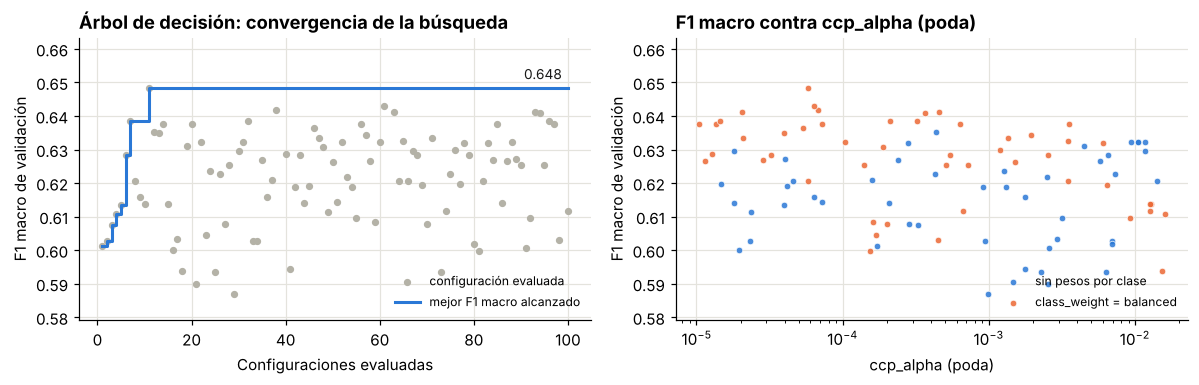

In [15]:
grafica_meseta(RESULTADOS["Árbol de decisión"], "Árbol de decisión", "clf__ccp_alpha",
               "ccp_alpha (poda)", escala_log=True, color_por="clf__class_weight",
               nombres_grupo={"None": "sin pesos por clase", "balanced": "class_weight = balanced"})

**Resultado.** La mejor configuración (F1 macro = 0.648 ± 0.013) apareció en la configuración 11. Las 89 restantes no la superaron: el mejor valor alcanzado es una meseta desde muy temprano. Las mejores configuraciones comparten un patrón claro:
- `class_weight = balanced` en las cinco mejores; en la gráfica de la derecha, los puntos naranjas (pesos balanceados) ocupan la parte alta.
- Profundidad moderada (7 en la mejor).
- Hojas grandes (`min_samples_leaf` de 40 a 70).

Con hojas tan grandes, la prepoda ya controla la mayor parte de la complejidad, así que la poda por costo-complejidad tiene un efecto secundario: los mejores valores de `ccp_alpha` rondan 10⁻⁴, y una poda más fuerte no mejora el F1. En la tabla, "—" en `max_depth` significa sin límite de profundidad.

### 6.2 Naive Bayes

Naive Bayes supone que los atributos son independientes dada la clase, y cada variante modela los atributos de una forma distinta. Por eso **la variante decide el preprocesamiento**, y se buscan juntas variante, preprocesamiento y suavizado:

| Variante | Preprocesamiento | Suavizado |
|---|---|---|
| **Gaussiana** | nominales en *one-hot*; numéricos sin cambio (la verosimilitud gaussiana no depende de la escala) | `var_smoothing` log-uniforme en [10⁻¹², 10⁻¹] |
| **Bernoulli** | todo binario: nominales en *one-hot* y numéricos **discretizados** por cuantiles en `n_bins` intervalos, también en *one-hot* | `alpha` (Laplace/Lidstone) log-uniforme en [10⁻³, 10] |
| **Categórica** | cada atributo como una categoría: nominales con su código (niveles raros agrupados) y numéricos **discretizados** por cuantiles en `n_bins` intervalos | `alpha` log-uniforme en [10⁻³, 10] |

`n_bins` va de 3 a 10. La discretización es necesaria en las variantes Bernoulli y categórica, que solo aceptan atributos discretos, y evita suponer normalidad en atributos muy sesgados (los conteos de unidades, con muchos ceros). Naive Bayes no admite `class_weight`; el desbalance entra a través de las probabilidades *a priori* de cada clase. Se evalúan **100 configuraciones**, repartidas al azar entre las tres variantes.

In [16]:
def prep_nb_gaussiano(numericas):
    return ColumnTransformer([
        ("nom", codificador_onehot(), NOMINALES),
        ("resto", "passthrough", BINARIAS + ORDINALES + numericas),
    ])

def prep_nb_bernoulli(numericas):
    return ColumnTransformer([
        ("nom", codificador_onehot(), NOMINALES),
        ("bin", "passthrough", BINARIAS),
        ("num", KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile"), ORDINALES + numericas),
    ])

def prep_nb_categorico(numericas):
    return ColumnTransformer([
        ("nom", CodificadorCategorico(), NOMINALES),
        ("bin", "passthrough", BINARIAS),
        ("num", KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile"), ORDINALES + numericas),
    ])

def pipeline_nb(numericas):
    return Pipeline([("prep", prep_nb_gaussiano(numericas)), ("clf", GaussianNB())])

def espacio_nb(numericas):
    return [
        {"prep": [prep_nb_gaussiano(numericas)], "clf": [GaussianNB()],
         "clf__var_smoothing": loguniform(1e-12, 1e-1)},
        {"prep": [prep_nb_bernoulli(numericas)], "clf": [BernoulliNB()],
         "prep__num__n_bins": randint(3, 11), "clf__alpha": loguniform(1e-3, 10)},
        {"prep": [prep_nb_categorico(numericas)], "clf": [CategoricalNB()],
         "prep__num__n_bins": randint(3, 11), "clf__alpha": loguniform(1e-3, 10)},
    ]

res = buscar("Naive Bayes", pipeline_nb(NUMERICAS), espacio_nb(NUMERICAS), N_ITER["Naive Bayes"], X, y)
cvr = pd.DataFrame(res["busqueda"].cv_results_)
variante = cvr["param_clf"].map(legible)
display(pd.DataFrame({"configuraciones": variante.value_counts(),
                      "mejor F1 macro": cvr.groupby(variante)["mean_test_score"].max().round(4)}))
mejores_configuraciones(res)

Naive Bayes: 100 configuraciones en 13 s
Mejor F1 macro de validación: 0.6274 ± 0.0132 (configuración 5)


,configuraciones,mejor F1 macro
param_clf,,
BernoulliNB,33,0.6217
CategoricalNB,40,0.6274
GaussianNB,27,0.5695


,clf,alpha,num__n_bins,var_smoothing,F1 macro,desv. est.
config,,,,,,
5,CategoricalNB,0.001209,4,nan,0.6274,0.01319
18,CategoricalNB,0.5408,6,nan,0.6264,0.007131
44,CategoricalNB,1.104,4,nan,0.6264,0.01474
20,CategoricalNB,4.338,6,nan,0.6244,0.008574
41,CategoricalNB,0.2318,8,nan,0.6242,0.009427


En la gráfica de la derecha, el suavizado de la variante gaussiana (`var_smoothing`) se dibuja en el mismo eje que `alpha` de las otras dos variantes.

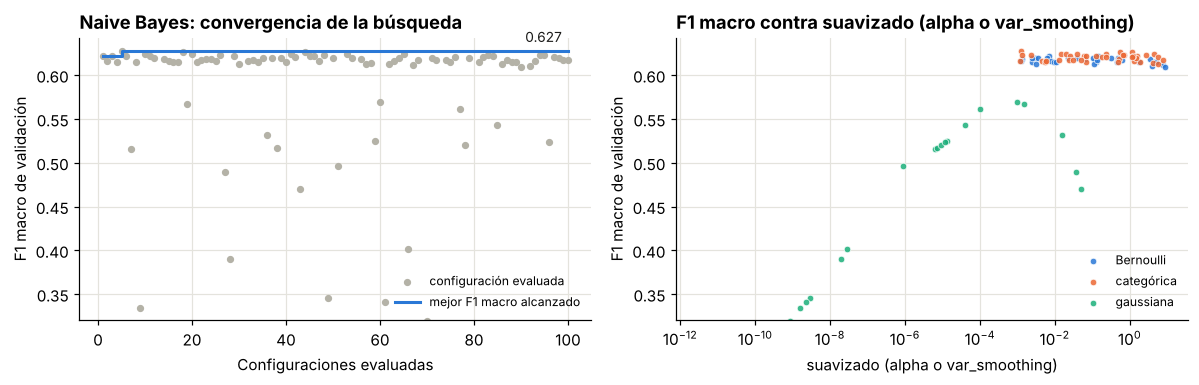

In [17]:
# Para graficar, un solo eje de 'suavizado': alpha en Bernoulli/categórica y var_smoothing en la gaussiana
cvr_nb = RESULTADOS["Naive Bayes"]["busqueda"].cv_results_
suav = [a if a is not np.ma.masked else v for a, v in
        zip(np.ma.asarray(cvr_nb["param_clf__alpha"]), np.ma.asarray(cvr_nb["param_clf__var_smoothing"]))]
cvr_nb["param_suavizado"] = np.ma.MaskedArray(suav, dtype=object)
grafica_meseta(RESULTADOS["Naive Bayes"], "Naive Bayes", "suavizado", "suavizado (alpha o var_smoothing)",
               escala_log=True, color_por="clf",
               nombres_grupo={"GaussianNB": "gaussiana", "BernoulliNB": "Bernoulli", "CategoricalNB": "categórica"})

**Resultado.** Naive Bayes llega a su mejor F1 macro (0.627 ± 0.013) desde la configuración 5, con la variante **categórica**, 4 intervalos y un suavizado mínimo. Después de eso ya no mejora. La variante Bernoulli queda muy cerca (0.622), y la gaussiana es claramente peor (0.570), lo cual era de esperarse: ni las columnas *one-hot* ni los conteos de unidades (con muchos ceros) se parecen a una distribución normal.

En las variantes discretas, el suavizado casi no influye: el F1 se mantiene igual a lo largo de tres órdenes de magnitud de `alpha`. La meseta llega tan pronto porque lo que limita a Naive Bayes no son sus hiperparámetros, sino el supuesto de independencia. Las seis variables del primer semestre (inscritas, evaluadas, aprobadas, promedio…) están fuertemente correlacionadas, y Naive Bayes cuenta varias veces la misma evidencia.

### 6.3 k vecinos más cercanos (kNN)

**Preprocesamiento.** kNN clasifica por distancias, así que todos los atributos deben estar en escalas comparables y sin un orden artificial:
- Nominales en *one-hot*. Con el código entero, dos carreras con códigos cercanos quedarían "cerca" sin razón.
- Numéricos y ordinal **escalados**. Sin escalar, la nota de admisión (95 a 190) dominaría la distancia frente a las unidades aprobadas (0 a 26). El tipo de escalador se incluye en la búsqueda: estandarización (media 0, desviación 1) o min-max (0 a 1, la misma escala que los binarios y el *one-hot*).
- Binarios sin cambio (0/1).

kNN no admite `class_weight`; la ponderación por distancia es su forma de dar más peso a los vecinos más parecidos.

**Espacio de búsqueda (100 configuraciones).**

| Hiperparámetro | Valores |
|---|---|
| `n_neighbors` (k) | 1 a 80 |
| `weights` | uniform, distance |
| distancia | Manhattan (Minkowski p = 1), euclidiana (p = 2), Chebyshev |
| escalador | estandarización, min-max |

In [18]:
def pipeline_distancias(numericas, clf):
    # Preprocesamiento común a kNN, SVM y regresión logística
    prep = ColumnTransformer([
        ("nom", codificador_onehot(), NOMINALES),
        ("bin", "passthrough", BINARIAS),
        ("num", StandardScaler(), ORDINALES + numericas),
    ])
    return Pipeline([("prep", prep), ("clf", clf)])

def pipeline_knn(numericas):
    return pipeline_distancias(numericas, KNeighborsClassifier())

def espacio_knn(numericas):
    comun = {"clf__n_neighbors": randint(1, 81), "clf__weights": ["uniform", "distance"],
             "prep__num": [StandardScaler(), MinMaxScaler()]}
    return [
        {**comun, "clf__metric": ["minkowski"], "clf__p": [1, 2]},
        {**comun, "clf__metric": ["chebyshev"]},
    ]

res = buscar("kNN", pipeline_knn(NUMERICAS), espacio_knn(NUMERICAS), N_ITER["kNN"], X, y)
mejores_configuraciones(res)

kNN: 100 configuraciones en 69 s
Mejor F1 macro de validación: 0.5740 ± 0.0164 (configuración 30)


,metric,n_neighbors,p,weights,num,F1 macro,desv. est.
config,,,,,,,
30,minkowski,8,1,uniform,StandardScaler,0.574,0.01636
96,minkowski,6,1,distance,StandardScaler,0.5549,0.007608
100,minkowski,18,1,distance,StandardScaler,0.5513,0.02113
52,minkowski,9,2,uniform,StandardScaler,0.5465,0.006817
4,minkowski,24,1,distance,StandardScaler,0.5369,0.01833


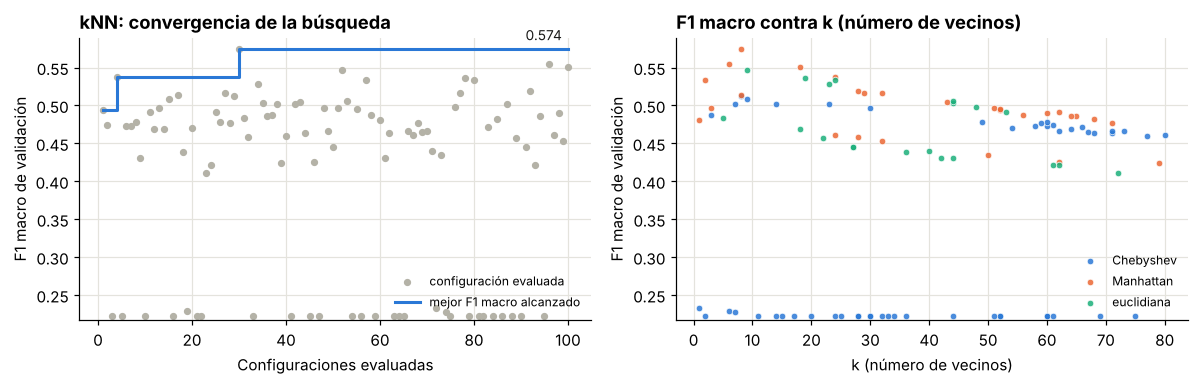

In [19]:
cvr_knn = RESULTADOS["kNN"]["busqueda"].cv_results_
dist = [("Chebyshev" if m == "chebyshev" else ("Manhattan" if p == 1 else "euclidiana"))
        for m, p in zip(np.ma.asarray(cvr_knn["param_clf__metric"]), np.ma.asarray(cvr_knn["param_clf__p"]))]
cvr_knn["param_distancia"] = np.ma.MaskedArray(dist, dtype=object)
grafica_meseta(RESULTADOS["kNN"], "kNN", "clf__n_neighbors", "k (número de vecinos)", color_por="distancia")

**Resultado.** El mejor kNN (F1 macro = 0.574 ± 0.016) usa k = 8, distancia Manhattan, votos sin ponderar y estandarización. Apareció en la configuración 30, y las 70 siguientes no lo superaron. kNN prefiere valores pequeños de k: con k grande, la clase mayoritaria (*graduado*) domina el voto y la clase *inscrito* casi desaparece. Todas las configuraciones con F1 ≈ 0.22, que predicen prácticamente solo *graduado*, usan la distancia Chebyshev. Con Chebyshev la distancia la decide un único atributo, el que más difiere; con más de cien columnas, eso casi no discrimina entre estudiantes. La distancia Manhattan, que suma las diferencias de todos los atributos, es la que mejor funciona.

### 6.4 Máquinas de soporte vectorial (SVM)

**Preprocesamiento.** Es el mismo que el de kNN, con estandarización: el SVM también depende de distancias y productos punto (el kernel RBF usa ‖x − x′‖²), así que la escala y la codificación importan por las mismas razones. La estandarización además mejora el condicionamiento del problema de optimización. El SVM multiclase de scikit-learn (`SVC`) combina clasificadores uno contra uno.

**Espacio de búsqueda (60 configuraciones), un subespacio por kernel.**

| Kernel | `C` | `gamma` | otros |
|---|---|---|---|
| RBF | log-uniforme [10⁻², 10³] | log-uniforme [10⁻⁴, 1] | — |
| polinomial | log-uniforme [10⁻², 10²] | log-uniforme [10⁻⁴, 5·10⁻²] | grado 2 o 3; `coef0` 0 o 1 |
| lineal | log-uniforme [10⁻³, 10] | no aplica | — |

En los tres kernels se busca además `class_weight` (ninguno o balanced). Los rangos de `C` del kernel lineal y de `gamma` del polinomial se acotaron porque, fuera de ellos, el optimizador tarda mucho más en converger sin mejorar el F1.

In [20]:
def pipeline_svm(numericas):
    return pipeline_distancias(numericas, SVC(cache_size=1000, random_state=SEMILLA))

def espacio_svm(numericas):
    pesos = [None, "balanced"]
    return [
        {"clf__kernel": ["rbf"], "clf__C": loguniform(1e-2, 1e3), "clf__gamma": loguniform(1e-4, 1),
         "clf__class_weight": pesos},
        {"clf__kernel": ["poly"], "clf__degree": [2, 3], "clf__coef0": [0.0, 1.0],
         "clf__C": loguniform(1e-2, 1e2), "clf__gamma": loguniform(1e-4, 5e-2), "clf__class_weight": pesos},
        {"clf__kernel": ["linear"], "clf__C": loguniform(1e-3, 10), "clf__class_weight": pesos},
    ]

res = buscar("SVM", pipeline_svm(NUMERICAS), espacio_svm(NUMERICAS), N_ITER["SVM"], X, y)
mejores_configuraciones(res)

SVM: 60 configuraciones en 113 s
Mejor F1 macro de validación: 0.6823 ± 0.0092 (configuración 12)


,C,class_weight,kernel,coef0,degree,gamma,F1 macro,desv. est.
config,,,,,,,,
12,62.45,balanced,poly,1,3,0.001097,0.6823,0.009189
20,72.61,balanced,poly,1,2,0.0002401,0.6751,0.008229
59,0.1465,balanced,linear,nan,nan,nan,0.6742,0.01305
19,0.8778,balanced,rbf,nan,nan,0.01441,0.6732,0.01322
18,0.1212,balanced,linear,nan,nan,nan,0.6725,0.01266


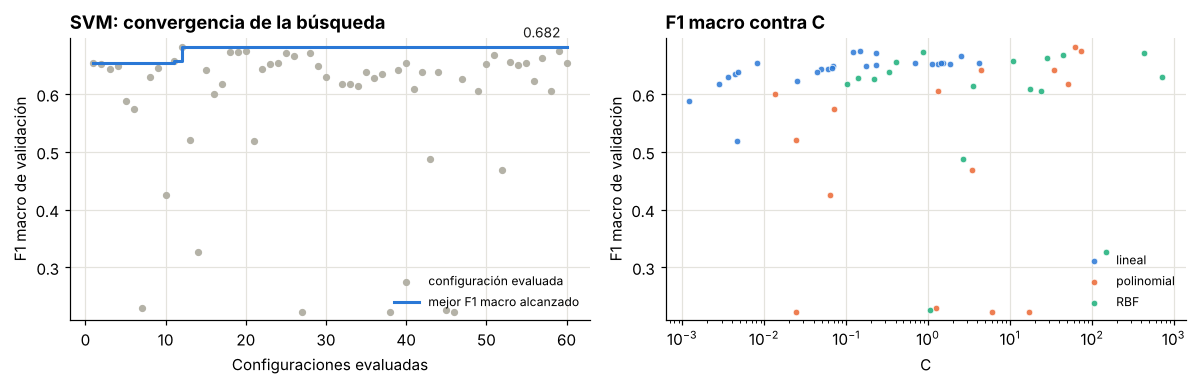

In [21]:
grafica_meseta(RESULTADOS["SVM"], "SVM", "clf__C", "C", escala_log=True, color_por="clf__kernel",
               nombres_grupo={"rbf": "RBF", "poly": "polinomial", "linear": "lineal"})

**Resultado.** El mejor SVM (F1 macro = 0.682 ± 0.009) usa un kernel **polinomial de grado 3** con `coef0 = 1`, `gamma` pequeño (0.0011), `C = 62` y `class_weight = balanced`. Apareció en la configuración 12, y las 48 siguientes no lo superaron. Los tres kernels llegan a resultados muy parecidos: el mejor lineal obtiene 0.674 y el mejor RBF 0.673. Que el lineal esté a menos de 0.01 del mejor indica que la frontera entre clases es casi lineal en este espacio, y que el polinomial con `gamma` pequeño solo agrega una curvatura leve. Las cinco mejores configuraciones usan pesos balanceados. Las configuraciones con F1 ≈ 0.22 son combinaciones de `C` y `gamma` con las que el modelo predice solo la clase mayoritaria.

### 6.5 Regresión logística

**Preprocesamiento.** Es el mismo que el del SVM:
- *One-hot* en los nominales, porque el modelo es lineal en sus entradas, y un coeficiente sobre un código entero supondría que el efecto crece con el código.
- Estandarización de los numéricos, porque la penalización (L1 o L2) actúa sobre la magnitud de los coeficientes y solo es justa si todos los atributos están en la misma escala. También acelera la convergencia del optimizador.

El modelo es multinomial (*softmax*) sobre las tres clases.

**Tipo de regularización.** En scikit-learn ≥ 1.8 el tipo se controla con `l1_ratio`: 0 es L2 (*ridge*), 1 es L1 (*lasso*) y un valor intermedio es *elastic net*. Se usa el solucionador `saga`, el único que admite los tres tipos en el caso multinomial.

**Espacio de búsqueda (60 configuraciones).**

| Hiperparámetro | Valores |
|---|---|
| tipo de regularización | L2, L1 o *elastic net* (`l1_ratio` uniforme en [0, 1]), un tercio de las configuraciones cada uno |
| `C` (inverso de la fuerza de regularización) | log-uniforme [10⁻³, 10²] |
| `class_weight` | ninguno, balanced |

In [22]:
VERSION_SK = tuple(int(v) for v in sklearn.__version__.split(".")[:2])

def regresion_logistica(**kw):
    # En scikit-learn < 1.8 hay que pedir penalty="elasticnet" para que l1_ratio tenga efecto
    extra = {} if VERSION_SK >= (1, 8) else {"penalty": "elasticnet"}
    return LogisticRegression(solver="saga", max_iter=3000, tol=1e-3, random_state=SEMILLA, **extra, **kw)

def pipeline_lr(numericas):
    return pipeline_distancias(numericas, regresion_logistica())

def espacio_lr(numericas):
    comun = {"clf__C": loguniform(1e-3, 1e2), "clf__class_weight": [None, "balanced"]}
    return [
        {**comun, "clf__l1_ratio": [0.0]},           # L2
        {**comun, "clf__l1_ratio": [1.0]},           # L1
        {**comun, "clf__l1_ratio": uniform(0, 1)},   # elastic net
    ]

res = buscar("Regresión logística", pipeline_lr(NUMERICAS), espacio_lr(NUMERICAS),
             N_ITER["Regresión logística"], X, y)
mejores_configuraciones(res)

Regresión logística: 60 configuraciones en 156 s
Mejor F1 macro de validación: 0.6801 ± 0.0092 (configuración 39)


,C,class_weight,l1_ratio,F1 macro,desv. est.
config,,,,,
39,0.1373,balanced,0.4393,0.6801,0.009219
18,0.1336,balanced,1,0.6768,0.008824
17,0.09022,balanced,1,0.676,0.01451
2,0.9644,balanced,0,0.676,0.005479
41,0.349,balanced,0,0.6759,0.005906


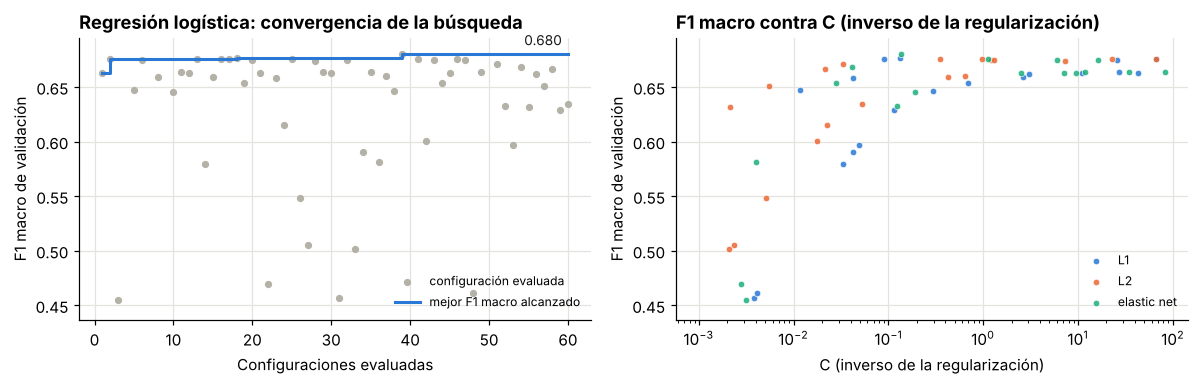

In [23]:
cvr_lr = RESULTADOS["Regresión logística"]["busqueda"].cv_results_
tipo = ["L2" if r == 0 else "L1" if r == 1 else "elastic net" for r in np.ma.asarray(cvr_lr["param_clf__l1_ratio"])]
cvr_lr["param_regularizacion"] = np.ma.MaskedArray(tipo, dtype=object)
grafica_meseta(RESULTADOS["Regresión logística"], "Regresión logística", "clf__C",
               "C (inverso de la regularización)", escala_log=True, color_por="regularizacion")

**Resultado.** La mejor regresión logística (F1 macro = 0.680 ± 0.009) usa *elastic net* (`l1_ratio = 0.44`), `C = 0.14` y `class_weight = balanced`, y apareció en la configuración 39. El tipo de regularización casi no importa: las mejores configuraciones L1, L2 y *elastic net* están a menos de 0.005 entre sí. Lo que sí importa es `C`: con regularización muy fuerte (`C` < 0.01), los coeficientes se encogen tanto que el F1 cae hasta 0.45. A partir de `C` ≈ 0.1, el F1 queda en una meseta de alrededor de 0.67–0.68. También aquí todas las mejores configuraciones usan pesos balanceados.

## 7. Comparación de los clasificadores optimizados

Cada clasificador se evalúa con su mejor configuración sobre los mismos cinco pliegues. El F1 macro es la media y la desviación estándar entre pliegues. La sensibilidad (*recall*) y la especificidad de cada clase son uno contra el resto y se promedian entre pliegues. El tiempo es el de la búsqueda completa (todas las configuraciones × 5 pliegues, más el reajuste final), con los núcleos disponibles en la máquina donde se ejecutó.

*Advertencia:* como los mismos pliegues sirven para elegir la configuración y para evaluarla, estos F1 son ligeramente optimistas. La comparación sigue siendo justa porque todos los clasificadores tienen el mismo sesgo y un presupuesto de búsqueda similar.

In [24]:
NOMBRES = list(RESULTADOS)
filas = []
for nombre in NOMBRES:
    r = RESULTADOS[nombre]
    pp = r["por_pliegue"]
    fila = {"F1 macro (media)": pp["f1_macro"].mean(), "F1 macro (desv. est.)": pp["f1_macro"].std()}
    for c in CLASES:
        fila[f"sens. {NOMBRES_CLASE[c].lower()}"] = pp[f"sens_{c}"].mean()
    for c in CLASES:
        fila[f"esp. {NOMBRES_CLASE[c].lower()}"] = pp[f"esp_{c}"].mean()
    fila["configuraciones"] = r["n_config"]
    fila["tiempo de búsqueda (s)"] = r["tiempo_busqueda_s"]
    filas.append(fila)

comparacion = pd.DataFrame(filas, index=NOMBRES).sort_values("F1 macro (media)", ascending=False)
MEJOR = comparacion.index[0]
comparacion.round(3)

,F1 macro (media),F1 macro (desv. est.),sens. desertor,sens. inscrito,sens. graduado,esp. desertor,esp. inscrito,esp. graduado,configuraciones,tiempo de búsqueda (s)
SVM,0.682,0.010,0.675,0.603,0.796,0.924,0.818,0.848,60,113.336
Regresión logística,0.680,0.010,0.697,0.570,0.793,0.919,0.826,0.840,60,155.745
Árbol de decisión,0.648,0.014,0.630,0.595,0.752,0.936,0.769,0.836,100,15.265
Naive Bayes,0.627,0.015,0.718,0.402,0.765,0.837,0.881,0.786,100,13.010
kNN,0.574,0.018,0.594,0.216,0.898,0.899,0.933,0.603,100,69.384


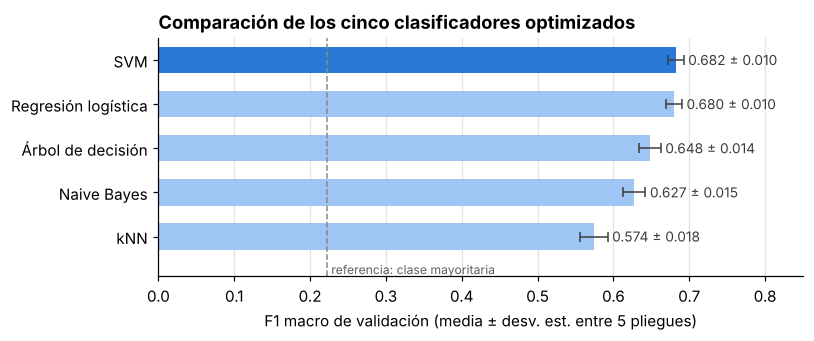

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
orden = comparacion.index[::-1]
medias = comparacion.loc[orden, "F1 macro (media)"]
desv = comparacion.loc[orden, "F1 macro (desv. est.)"]
colores = ["#2a78d6" if n == MEJOR else "#9ec5f4" for n in orden]
ax.barh(range(len(orden)), medias, xerr=desv, color=colores, height=0.6,
        error_kw=dict(ecolor="#3d3d3a", capsize=3, linewidth=1))
for i, (m, s) in enumerate(zip(medias, desv)):
    ax.text(m + s + 0.006, i, f"{m:.3f} ± {s:.3f}", va="center", fontsize=9, color="#3d3d3a")
ref = ref_por_pliegue["f1_macro"].mean()
ax.axvline(ref, color="#8a8980", linestyle="--", linewidth=1)
ax.set_ylim(-0.9, len(orden) - 0.5)
ax.text(ref + 0.006, -0.75, "referencia: clase mayoritaria", fontsize=8, color="#5f5e5a", va="center")
ax.set_yticks(range(len(orden)), orden)
ax.set_xlim(0, 0.85)
ax.set_xlabel("F1 macro de validación (media ± desv. est. entre 5 pliegues)")
ax.grid(axis="y", visible=False)
ax.set_title("Comparación de los cinco clasificadores optimizados")
plt.tight_layout()
plt.show()

In [26]:
# ¿Es clara la diferencia entre los dos mejores? Diferencias pareadas por pliegue
primero, segundo = comparacion.index[:2]
dif = RESULTADOS[primero]["por_pliegue"]["f1_macro"] - RESULTADOS[segundo]["por_pliegue"]["f1_macro"]
print(f"{primero} − {segundo}, por pliegue: {np.round(dif.values, 4)}")
print(f"Diferencia media: {dif.mean():.4f} ± {dif.std():.4f}; {primero} gana en {(dif > 0).sum()} de {N_PLIEGUES} pliegues")

SVM − Regresión logística, por pliegue: [ 0.014   0.0147  0.0006 -0.0098 -0.0082]
Diferencia media: 0.0023 ± 0.0117; SVM gana en 3 de 5 pliegues


**Comparación.** Hay tres grupos claros:

1. **SVM (0.682) y regresión logística (0.680) están empatados en la práctica.** La diferencia media es 0.002, mucho menor que su variación entre pliegues (± 0.012), y el SVM gana solo en 3 de 5 pliegues. Ambos son modelos de frontera lineal o casi lineal, y ambos aprovechan `class_weight` para no descuidar la clase *inscrito* (sensibilidad de 0.60 y 0.57).
2. **El árbol (0.648) y Naive Bayes (0.627)** quedan 3 a 5 puntos por debajo. El árbol modela bien las interacciones, pero cada hoja estima la clase con pocos datos. Naive Bayes detecta bien a los desertores (sensibilidad de 0.72, la más alta), pero falla con los inscritos (0.40), porque los asigna a los extremos.
3. **kNN (0.574)** es claramente el peor. Predice *graduado* en exceso (sensibilidad de 0.90 pero especificidad de solo 0.60) y casi nunca reconoce a los inscritos (0.22). En más de cien dimensiones, con la mitad de los estudiantes graduados, los vecinos de casi cualquier estudiante son mayoritariamente graduados.

En todos los clasificadores, *inscrito* es la clase más difícil. En tiempo, el SVM y la regresión logística son los más costosos (2 a 2.5 minutos de búsqueda), y el árbol y Naive Bayes los más baratos (unos 15 s).

El **mejor clasificador** según el criterio establecido (mayor F1 macro medio) es el **SVM**, que se usa en las secciones siguientes. La regresión logística sería una alternativa igual de buena y más interpretable.

## 8. Matriz de confusión del mejor clasificador y análisis de la clase desertor

La matriz se construye con las **predicciones de validación cruzada**: cada estudiante se predice con el modelo entrenado en los pliegues en los que no participó, de modo que ninguna predicción se hizo con un modelo que ya hubiera visto a ese estudiante.

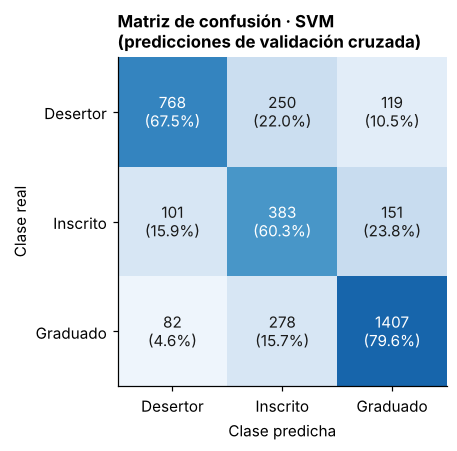

,pred.: Desertor,pred.: Inscrito,pred.: Graduado
real: Desertor,768,250,119
real: Inscrito,101,383,151
real: Graduado,82,278,1407


In [27]:
pred_mejor = RESULTADOS[MEJOR]["pred_oof"]
cm = confusion_matrix(y, pred_mejor, labels=CLASES)
cm_fila = cm / cm.sum(axis=1, keepdims=True)
etq = [NOMBRES_CLASE[c] for c in CLASES]

fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(cm_fila, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]}\n({cm_fila[i, j]:.1%})", ha="center", va="center", fontsize=10,
                color="white" if cm_fila[i, j] > 0.55 else "#1a1a19")
ax.set_xticks(range(3), etq)
ax.set_yticks(range(3), etq)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.grid(False)
ax.set_title(f"Matriz de confusión · {MEJOR}\n(predicciones de validación cruzada)", fontsize=11)
plt.tight_layout()
plt.show()

pd.DataFrame(cm, index=[f"real: {e}" for e in etq], columns=[f"pred.: {e}" for e in etq])

Para entender **por qué** se confunden los desertores, se compara el perfil de los desertores según la clase que les asignó el modelo con el perfil típico de los inscritos y de los graduados reales.

In [28]:
grupo = pd.Series(np.nan, index=y.index, dtype=object)
mask_d = y == "dropout"
grupo[mask_d] = "desertor → " + pred_mejor[mask_d].map(lambda c: NOMBRES_CLASE[c].lower())
grupo[y == "enrolled"] = "inscritos reales"
grupo[y == "graduate"] = "graduados reales"
orden_grupos = ["desertor → desertor", "desertor → inscrito", "desertor → graduado",
                "inscritos reales", "graduados reales"]

perfil = entrenamiento.assign(grupo=grupo,
    pct_aprobado=lambda d: np.where(d["Curricular units 1st sem (enrolled)"] > 0,
        d["Curricular units 1st sem (approved)"] / d["Curricular units 1st sem (enrolled)"], np.nan))
tabla_perfil = perfil.groupby("grupo").agg(**{
    "estudiantes": ("id", "size"),
    "unidades inscritas (1er sem.)": ("Curricular units 1st sem (enrolled)", "mean"),
    "unidades aprobadas (1er sem.)": ("Curricular units 1st sem (approved)", "mean"),
    "% de inscritas aprobadas": ("pct_aprobado", "mean"),
    "promedio (0–20)": ("Curricular units 1st sem (grade)", "mean"),
    "% con 0 aprobadas": ("Curricular units 1st sem (approved)", lambda s: (s == 0).mean()),
    "% colegiatura al día": ("Tuition fees up to date", "mean"),
    "% becados": ("Scholarship holder", "mean"),
    "edad al ingresar": ("Age at enrollment", "mean"),
}).reindex(orden_grupos)
for c in ["% de inscritas aprobadas", "% con 0 aprobadas", "% colegiatura al día", "% becados"]:
    tabla_perfil[c] = 100 * tabla_perfil[c]
tabla_perfil.round(1)

,estudiantes,unidades inscritas (1er sem.),unidades aprobadas (1er sem.),% de inscritas aprobadas,promedio (0–20),% con 0 aprobadas,% colegiatura al día,% becados,edad al ingresar
grupo,,,,,,,,,
desertor → desertor,768,5.8,1.7,26.1,5.5,54.4,52.9,6.1,27.6
desertor → inscrito,250,5.7,3.4,59.9,10.8,9.2,96.0,10.0,22.9
desertor → graduado,119,6.7,6.2,93.4,12.2,5.9,99.2,31.9,22.8
inscritos reales,635,6.0,4.3,71.1,11.1,9.0,95.1,16.5,22.3
graduados reales,1767,6.7,6.2,93.5,12.6,3.7,98.7,38.1,21.8


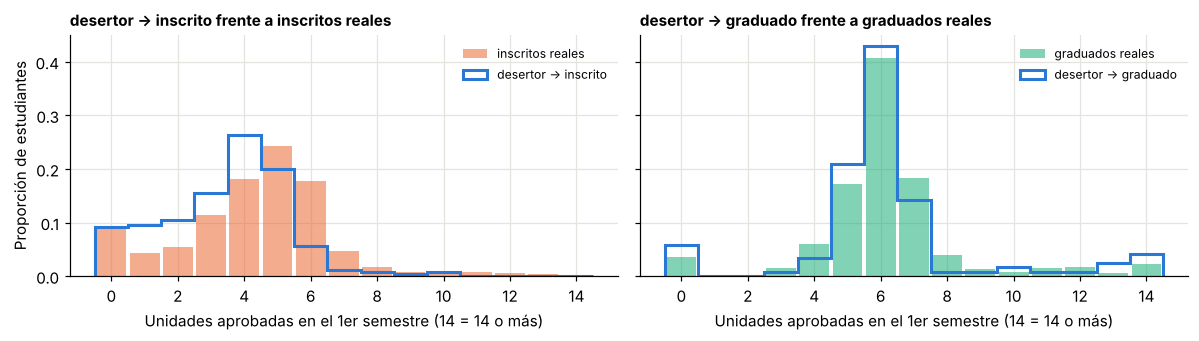

In [29]:
# Distribución de unidades aprobadas: desertores mal clasificados frente a la clase con la que se confunden
col = "Curricular units 1st sem (approved)"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
bins = np.arange(0, 16) - 0.5
for ax, (g_err, g_ref, c_ref) in zip(axes, [("desertor → inscrito", "inscritos reales", "enrolled"),
                                           ("desertor → graduado", "graduados reales", "graduate")]):
    a = perfil.loc[perfil["grupo"] == g_err, col].clip(upper=14)
    b = perfil.loc[perfil["grupo"] == g_ref, col].clip(upper=14)
    ax.hist(b, bins=bins, density=True, color=COLOR_CLASE[c_ref], alpha=0.55, label=g_ref, rwidth=0.9)
    ax.hist(a, bins=bins, density=True, histtype="step", linewidth=2, color=COLOR_CLASE["dropout"], label=g_err)
    ax.set_xlabel("Unidades aprobadas en el 1er semestre (14 = 14 o más)")
    ax.legend(fontsize=8, frameon=False)
    ax.set_title(f"{g_err} frente a {g_ref}", fontsize=10)
axes[0].set_ylabel("Proporción de estudiantes")
plt.tight_layout()
plt.show()

**Análisis de la clase desertor.** El SVM reconoce a 768 de los 1137 desertores (67.5 %). De los 369 que se le escapan, **250 (22 %) los confunde con *inscrito*** y 119 (10.5 %) con *graduado*. La tabla de perfiles explica por qué:

- **Los desertores que sí detecta** tienen un primer semestre muy malo: aprueban en promedio 1.7 unidades de 5.8, más de la mitad no aprueba ninguna, solo el 53 % tiene la colegiatura al día, y en promedio son mayores (27.6 años al ingresar).
- **Los desertores confundidos con *inscrito*** aprobaron el 60 % de sus unidades, con un promedio de 10.8, y el 96 % tiene la colegiatura al día. Es casi el mismo perfil de los inscritos reales (71 %, 11.1, 95 %), y en la primera gráfica sus distribuciones de unidades aprobadas se traslapan casi por completo. Al cierre del primer semestre, un estudiante que va "regular" puede terminar desertando o seguir inscrito más tiempo del normal. Lo que distingue ambos destinos ocurre después, y no está en los datos.
- **Los desertores confundidos con *graduado*** son indistinguibles de los graduados en el primer semestre: aprobaron el 93 % de sus unidades, con promedio de 12.2 y la colegiatura al día. Recordemos que *Dropout* incluye los cambios de carrera o de institución en cualquier momento. Muchos de estos estudiantes no fracasan académicamente: se van más tarde o se cambian, por razones que ningún atributo del primer semestre registra.

En resumen, el modelo detecta bien la deserción por bajo rendimiento y por problemas de pago. La que no detecta ocurre en estudiantes con un primer semestre normal, y con la información disponible al momento de decidir ese error es en gran parte irreducible.

## 9. ¿Conviene esperar al cierre del segundo semestre?

Para estimar cuánto mejoraría el mejor clasificador si se esperara un semestre más, se repite **su misma búsqueda** (mismo pipeline, mismo espacio, mismo número de configuraciones y mismos pliegues) sobre el conjunto de entrenamiento con los 36 atributos: los 30 anteriores y los seis del segundo semestre (escalados igual que los demás numéricos). Así la diferencia se debe solo a la información adicional, y no a una optimización distinta. El conjunto de prueba no interviene, porque no trae esos atributos.

In [30]:
FABRICAS = {
    "Árbol de decisión": (pipeline_arbol, espacio_arbol),
    "Naive Bayes": (pipeline_nb, espacio_nb),
    "kNN": (pipeline_knn, espacio_knn),
    "SVM": (pipeline_svm, espacio_svm),
    "Regresión logística": (pipeline_lr, espacio_lr),
}
NUMERICAS_2DO = NUMERICAS + SEM2
fab_pipe, fab_esp = FABRICAS[MEJOR]
res_2do = buscar(f"{MEJOR} (2º semestre)", fab_pipe(NUMERICAS_2DO), fab_esp(NUMERICAS_2DO),
                 N_ITER[MEJOR], X_2do, y, guardar=False)

pp1 = RESULTADOS[MEJOR]["por_pliegue"]
pp2 = res_2do["por_pliegue"]
filas = {"F1 macro": "f1_macro", **{f"sens. {NOMBRES_CLASE[c].lower()}": f"sens_{c}" for c in CLASES},
         **{f"esp. {NOMBRES_CLASE[c].lower()}": f"esp_{c}" for c in CLASES}}
tabla_espera = pd.DataFrame({
    "cierre 1er semestre": [pp1[v].mean() for v in filas.values()],
    "cierre 2º semestre": [pp2[v].mean() for v in filas.values()],
}, index=filas.keys())
tabla_espera["diferencia"] = tabla_espera["cierre 2º semestre"] - tabla_espera["cierre 1er semestre"]

dif_f1 = pp2["f1_macro"] - pp1["f1_macro"]
print(f"Mejora del F1 macro por pliegue: {np.round(dif_f1.values, 4)}")
print(f"Mejora media: {dif_f1.mean():.4f} ± {dif_f1.std():.4f}; mejora en {(dif_f1 > 0).sum()} de {N_PLIEGUES} pliegues")
tabla_espera.round(3)

SVM (2º semestre): 60 configuraciones en 107 s
Mejor F1 macro de validación: 0.7165 ± 0.0089 (configuración 12)
Mejora del F1 macro por pliegue: [0.0164 0.044  0.0248 0.0623 0.0231]
Mejora media: 0.0341 ± 0.0188; mejora en 5 de 5 pliegues


,cierre 1er semestre,cierre 2º semestre,diferencia
F1 macro,0.682,0.716,0.034
sens. desertor,0.675,0.720,0.045
sens. inscrito,0.603,0.635,0.031
sens. graduado,0.796,0.823,0.027
esp. desertor,0.924,0.934,0.010
esp. inscrito,0.818,0.836,0.018
esp. graduado,0.848,0.871,0.024


,estudiantes
desertores en el entrenamiento,1137
detectados al cierre del 1er semestre,768
detectados al cierre del 2º semestre,819
detectados solo si se espera,88
detectados solo al cierre del 1er semestre,37
desertores sin unidades inscritas en el 2º semestre,60


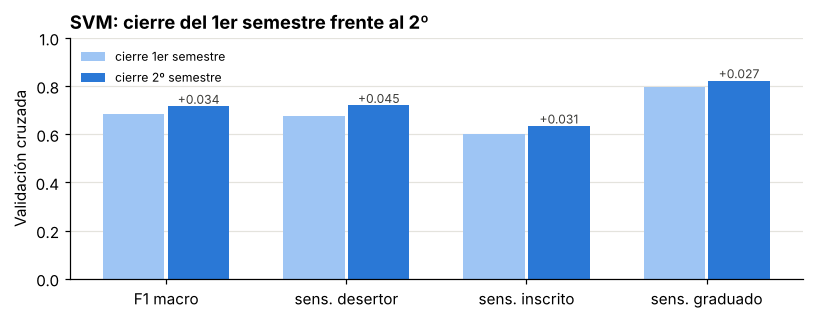

In [31]:
pred_2do = res_2do["pred_oof"]
d = y == "dropout"
det1, det2 = (pred_mejor == "dropout") & d, (pred_2do == "dropout") & d
detecciones = pd.Series({
    "desertores en el entrenamiento": d.sum(),
    "detectados al cierre del 1er semestre": det1.sum(),
    "detectados al cierre del 2º semestre": det2.sum(),
    "detectados solo si se espera": (det2 & ~det1).sum(),
    "detectados solo al cierre del 1er semestre": (det1 & ~det2).sum(),
    "desertores sin unidades inscritas en el 2º semestre": (d & (entrenamiento["Curricular units 2nd sem (enrolled)"] == 0)).sum(),
}, name="estudiantes")
display(detecciones.to_frame())

fig, ax = plt.subplots(figsize=(7.5, 3))
etiquetas = list(filas.keys())[:4]
xpos = np.arange(len(etiquetas))
ax.bar(xpos - 0.18, tabla_espera.loc[etiquetas, "cierre 1er semestre"], width=0.34, color="#9ec5f4", label="cierre 1er semestre")
ax.bar(xpos + 0.18, tabla_espera.loc[etiquetas, "cierre 2º semestre"], width=0.34, color="#2a78d6", label="cierre 2º semestre")
for i, e in enumerate(etiquetas):
    ax.text(i + 0.18, tabla_espera.loc[e, "cierre 2º semestre"] + 0.01,
            f"+{tabla_espera.loc[e, 'diferencia']:.3f}", ha="center", fontsize=8, color="#3d3d3a")
ax.set_xticks(xpos, etiquetas)
ax.set_ylim(0, 1)
ax.set_ylabel("Validación cruzada")
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title(f"{MEJOR}: cierre del 1er semestre frente al 2º")
plt.tight_layout()
plt.show()

**¿Conviene esperar?** Con los atributos del segundo semestre, el F1 macro del SVM sube de 0.682 a 0.716 (+0.034 ± 0.019) y mejora en los cinco pliegues, así que la mejora es real. La sensibilidad para *desertor* sube de 0.675 a 0.720: se detectarían 819 desertores en vez de 768. La ganancia neta es de 51 estudiantes (88 que solo se detectan esperando, menos 37 que se dejan de detectar), alrededor del 4.5 % de los desertores.

Sin embargo, **esperar no parece conveniente**, por tres razones:

1. **El costo es el tiempo.** Los 768 desertores que ya se detectan al cierre del primer semestre recibirían cualquier apoyo un semestre más tarde. Para muchos sería demasiado tarde: 60 de los desertores del entrenamiento ya no inscribieron ninguna unidad en el segundo semestre, es decir, ya se habían ido.
2. **La ganancia es modesta y en parte trivial.** Una parte de los desertores "nuevos" se detecta porque en el segundo semestre ya muestran el abandono (pocas o ninguna unidad inscrita o aprobada). Eso es constatar la deserción más que anticiparla.
3. **No son excluyentes.** La estrategia razonable es predecir al cierre del primer semestre para intervenir pronto, y volver a evaluar al cierre del segundo con el modelo de 36 atributos, como segundo filtro para los estudiantes que el primero no detectó.

## 10. Clasificador final y predicciones de prueba

El clasificador final es el mejor de la comparación, con su mejor configuración. `RandomizedSearchCV` ya lo reentrenó con **todo** el conjunto de entrenamiento (`refit=True`), usando únicamente los 30 atributos disponibles al cierre del primer semestre. Con él se predicen los 885 estudiantes de prueba y se escribe `predicciones.csv` con las columnas `id` y `Target`.

In [32]:
modelo_final = RESULTADOS[MEJOR]["modelo"]
print(f"Clasificador final: {MEJOR}")
print("Hiperparámetros:", ", ".join(f"{k.replace('clf__', '')} = {legible(v)}"
                                   for k, v in RESULTADOS[MEJOR]["busqueda"].best_params_.items()))

pred_prueba = modelo_final.predict(X_prueba)
entrega = pd.DataFrame({"id": prueba["id"], "Target": pred_prueba})
entrega.to_csv(RUTA_PREDICCIONES, index=False)

# Verificación del archivo escrito
leido = pd.read_csv(RUTA_PREDICCIONES)
assert list(leido.columns) == ["id", "Target"]
assert len(leido) == 885 and leido["id"].is_unique and set(leido["id"]) == set(prueba["id"])
assert set(leido["Target"]) <= set(CLASES) and leido["Target"].notna().all()
print(f"Archivo escrito y verificado: {RUTA_PREDICCIONES} ({len(leido)} filas, columnas {list(leido.columns)})")

pd.DataFrame({
    "entrenamiento (real)": y.value_counts(normalize=True).reindex(CLASES),
    "entrenamiento (predicción de validación)": pred_mejor.value_counts(normalize=True).reindex(CLASES),
    "prueba (predicción)": leido["Target"].value_counts(normalize=True).reindex(CLASES),
}).rename(index=NOMBRES_CLASE).round(3)

Clasificador final: SVM
Hiperparámetros: C = 62.45, class_weight = balanced, coef0 = 1, degree = 3, gamma = 0.001097, kernel = poly
Archivo escrito y verificado: predicciones.csv (885 filas, columnas ['id', 'Target'])


,entrenamiento (real),entrenamiento (predicción de validación),prueba (predicción)
Desertor,0.321,0.269,0.249
Inscrito,0.179,0.257,0.270
Graduado,0.499,0.474,0.481


In [33]:
leido.head()

,id,Target
0,6,graduate
1,12,graduate
2,15,graduate
3,18,enrolled
4,19,graduate


Las predicciones de prueba tienen una distribución muy parecida a la de las predicciones de validación cruzada en el entrenamiento (≈ 25 % desertores, 26–27 % inscritos, 48 % graduados), lo cual indica que el conjunto de prueba se comporta como el de entrenamiento. El modelo predice más *inscritos* de los que hay en realidad (27 % contra 18 %). Es el efecto esperado de `class_weight = balanced`: se sacrifica precisión en la clase minoritaria para ganar sensibilidad, y eso favorece al F1 macro. Por la sección 7, se espera un F1 macro de prueba cercano a 0.68, quizás un poco menor, porque la estimación de validación es ligeramente optimista.

## 11. Discusión y conclusiones

**Sobre cada clasificador en este problema:**

- **SVM (F1 macro = 0.682).** Es el mejor, empatado con la regresión logística. Su ventaja es poder usar una frontera ligeramente no lineal (kernel polinomial con `gamma` pequeño), aunque la frontera lineal ya captura casi todo. Es el más sensible a los hiperparámetros: varias combinaciones de `C` y `gamma` colapsan a predecir una sola clase, así que necesita una búsqueda cuidadosa. Su costo de búsqueda es de los más altos.
- **Regresión logística (0.680).** Prácticamente iguala al SVM con un modelo más simple, más rápido de predecir e interpretable (cada coeficiente indica cómo un atributo mueve el *log-odds* de cada clase). El tipo de regularización apenas influye; lo decisivo es no regularizar en exceso y balancear las clases. En una aplicación real sería una opción muy atractiva.
- **Árbol de decisión (0.648).** Es competitivo, rápido e interpretable, pero inestable: necesita hojas grandes para no sobreajustar, y entonces pierde resolución en la frontera entre *inscrito* y las otras dos clases.
- **Naive Bayes (0.627).** Es el más barato y el que más desertores detecta, pero el supuesto de independencia lo perjudica en un conjunto donde los seis atributos del semestre dicen casi lo mismo. Además, empuja a los inscritos hacia los extremos. Discretizar los numéricos (variante categórica) funcionó mejor que suponer normalidad.
- **kNN (0.574).** Es el que peor se adapta: los datos tienen muchas dimensiones *one-hot*, la clase mayoritaria domina los vecindarios y no hay forma de ponderar las clases. Su F1 está muy por encima de la referencia (0.22), pero muy por debajo del resto.

**Conclusiones generales.**

1. Con la información disponible al cierre del primer semestre, el mejor clasificador alcanza un F1 macro de validación de alrededor de 0.68. Detecta a dos de cada tres desertores, con una especificidad de 0.92 para esa clase.
2. La clase *inscrito* es la más difícil para todos los modelos. Es un estado intermedio, cuyo desempeño en el primer semestre se traslapa con el de las otras dos clases. Los pesos por clase (`class_weight = balanced`) fueron decisivos en los tres clasificadores que los admiten.
3. La deserción que el modelo no detecta corresponde a estudiantes con un primer semestre normal, que se van más tarde o se cambian de carrera. Con estos atributos, ese error es en buena medida irreducible.
4. Esperar al segundo semestre mejora el F1 macro en unos 3.4 puntos, pero retrasa la intervención para todos. Es preferible predecir al cierre del primer semestre y usar el segundo como un segundo filtro.

**Limitaciones.** Los F1 de validación son ligeramente optimistas, porque los mismos pliegues sirvieron para elegir y para evaluar cada configuración; una validación cruzada anidada daría una estimación sin sesgo, a cambio de un costo cinco veces mayor. Además, el presupuesto de búsqueda (60 a 100 configuraciones) es modesto para el SVM, que tiene el espacio más grande, aunque las gráficas muestran que todos los clasificadores llegaron a una meseta.

## Referencias

- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
- Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
- Pedregosa, F. *et al.* (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.